# Showing the data via scanpy

In [113]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram

In [114]:
adata = sc.read_h5ad("./source_data/seurat_curated_6dpf.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 30850 × 64955
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'seurat_clusters', 'S.Score', 'G2M.Score', 'Phase', 'clade_coarse_nj', 'vic_annotations', 'year_end_annotation_2022.coarse', 'cell_barcode', 'curated_48hpf.derived_annotations', 'biological_replicate', 'whitelisted_for_curation', 'nCount_SCT', 'nFeature_SCT', 'curated_high_res_annotations', 'coarse_clade_membership', 'celltype_family_20240924', 'group_full', 'group_slug', 'group_color', 'clade', 'subclade', 'subsubclade'
    uns: 'version'
    obsm: 'X_pca', 'X_umap'
    layers: 'RNA'


I have a 'RNA' layers instead of counts.

In [115]:
adata.layers['counts'] = adata.layers.pop('RNA')
adata.X = adata.layers['counts'].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

I do not need to redo the dimensionality reduction process, I saved it from Seurat...

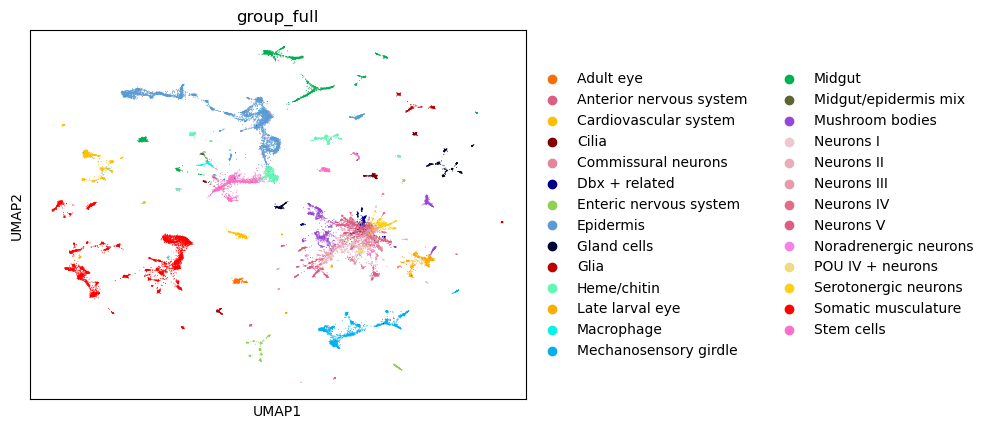

In [116]:
# I already have a defined color map
palette_dict = pd.Series(adata.obs['group_color'].values, index=adata.obs['group_full']).to_dict()
sc.pl.umap(
    adata,
    color="group_full",
    palette=palette_dict,
    size=2,
)

**In terms of metadata we care about:**
* `curated_high_res_annotations`:  Detlev's ~250 cell types (except 3 he likes but that are not in this curated object)
* `group_full`: Detlev's 20 or so big grouping, neurons are a bit hazy

I will reorder the types in a specific order.

In [117]:
cell_types_metadata = pd.read_csv("./prepped_data/subclade_ordering_color_scheme.tsv", sep="\t", index_col="sub_membership")

ordered_cell_types = cell_types_metadata.index.drop_duplicates().str.strip().tolist()
print(f"Extracted cell type order: {ordered_cell_types}")

adata.obs['curated_high_res_annotations'] = pd.Categorical(
    adata.obs['curated_high_res_annotations'],
    categories=ordered_cell_types,
    ordered=True
)

ordered_tissue_types = cell_types_metadata['group_full'].drop_duplicates().str.strip().tolist()
print(f"Extracted tissue type order: {ordered_tissue_types}")

adata.obs['group_full'] = pd.Categorical(
    adata.obs['group_full'],
    categories=ordered_tissue_types,
    ordered=True
)


Extracted cell type order: ['clade5sub7', 'clade13sub9', 'clade5sub16', 'clade5sub9', 'nocladesub1', 'clade5sub5', 'clade5sub12', 'clade7sub10', 'clade7sub6', 'clade2sub10', 'clade7sub8', 'clade6sub25', 'clade6sub27', 'clade6sub28', 'clade6sub26', 'nocladesub33', 'clade6sub22', 'nocladesub2', 'nocladesub10', 'nocladesub12', 'nocladesub26', 'nocladesub20', 'clade6sub19', 'clade6sub14', 'nocladesub4', 'nocladesub8', 'clade6sub24', 'clade6sub7', 'clade6sub23', 'clade6sub21', 'clade6sub16', 'clade6sub9', 'clade6sub13', 'clade6sub11', 'clade6sub15', 'clade6sub17', 'nocladesub24', 'nocladesub3', 'nocladesub11', 'nocladesub15', 'nocladesub25', 'nocladesub35', 'clade7sub7', 'clade1sub12', 'nocladesub22', 'clade1sub18', 'clade1sub17', 'clade1sub13', 'clade1sub4', 'clade1sub19', 'clade1sub11', 'clade1sub3', 'clade1sub16', 'clade1sub14', 'clade1sub7', 'clade1sub2', 'nocladesub9', 'nocladesub29', 'clade3.2sub22', 'clade3.2sub18', 'clade3.2sub14', 'clade3.2sub20', 'clade3.2sub13', 'clade3.2sub16', 

I will rename my features to `XLOC | symbol`.

In [118]:
genes_metadata = pd.read_csv("./prepped_data/genes_metadata.tsv", sep="\t")
genes_metadata

,Unnamed: 0,ProsPR gene,Published name,pdumV2-1,Platybrowser name,XLOC,XLOC_full
0,0,Glt1,Glt1,XLOC_001410,glt1,XLOC-001410,XLOC-001410 | glt1
1,2,ANPRA,NaN,XLOC_025950,anpra,XLOC-025950,XLOC-025950 | anpra
2,4,AP2,ap2,XLOC_002429,ap2,XLOC-002429,XLOC-002429 | ap2
3,5,ASCb,ASCb,XLOC_008377,ascb,XLOC-008377,XLOC-008377 | ascb
4,6,AllCR1,NaN,XLOC_022100,allcr1,XLOC-022100,XLOC-022100 | allcr1
...,...,...,...,...,...,...,...
171,197,brn124,NaN,XLOC_005393,brn124,XLOC-005393,XLOC-005393 | brn124
172,198,nompc3,NaN,XLOC_002090,nompc3,XLOC-002090,XLOC-002090 | nompc3
173,199,pkd1,PKD1-1,XLOC_027897,pkd1,XLOC-027897,XLOC-027897 | pkd1
174,200,pkd2,PKD2-1,XLOC_026080,pkd2,XLOC-026080,XLOC-026080 | pkd2


In [119]:
genes_lookup = dict(zip(genes_metadata['XLOC'], genes_metadata['XLOC_full']))
genes_lookup

{'XLOC-001410': 'XLOC-001410 | glt1',
 'XLOC-025950': 'XLOC-025950 | anpra',
 'XLOC-002429': 'XLOC-002429 | ap2',
 'XLOC-008377': 'XLOC-008377 | ascb',
 'XLOC-022100': 'XLOC-022100 | allcr1',
 'XLOC-025660': 'XLOC-025660 | allcr2',
 'XLOC-044659': 'XLOC-044659 | arx',
 'XLOC-004258': 'XLOC-004258 | ash',
 'XLOC-056544': 'XLOC-056544 | barh1',
 'XLOC-003898': 'XLOC-003898 | beta3',
 'XLOC-009861': 'XLOC-009861 | bmpr1',
 'XLOC-000129': 'XLOC-000129 | brn3a',
 'XLOC-028320': 'XLOC-028320 | coe',
 'XLOC-026597': 'XLOC-026597 | chat',
 'XLOC-021496': 'XLOC-021496 | chx10',
 'XLOC-003551': 'XLOC-003551 | dach',
 'XLOC-018534': 'XLOC-018534 | dbhlike',
 'XLOC-020366': 'XLOC-020366 | dopard2',
 'XLOC-053880': 'XLOC-053880 | pgam',
 'XLOC-015543': 'XLOC-015543 | upp',
 'XLOC-008954': 'XLOC-008954 | unc22',
 'XLOC-014514': 'XLOC-014514 | ndus1',
 'XLOC-021313': 'XLOC-021313 | odo2',
 'XLOC-018549': 'XLOC-018549 | fxl21',
 'XLOC-012281': 'XLOC-012281 | ryr2',
 'XLOC-001169': 'XLOC-001169 | ppib'

In [120]:
assert(not set(genes_lookup.keys()).difference(set(adata.var_names.to_list())))
subset_adata = adata[:, adata.var_names.isin(genes_lookup.keys())].copy()
subset_adata

AnnData object with n_obs × n_vars = 30850 × 174
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mtdna', 'percent.rrna', 'percent.goodgenes', 'seurat_clusters', 'S.Score', 'G2M.Score', 'Phase', 'clade_coarse_nj', 'vic_annotations', 'year_end_annotation_2022.coarse', 'cell_barcode', 'curated_48hpf.derived_annotations', 'biological_replicate', 'whitelisted_for_curation', 'nCount_SCT', 'nFeature_SCT', 'curated_high_res_annotations', 'coarse_clade_membership', 'celltype_family_20240924', 'group_full', 'group_slug', 'group_color', 'clade', 'subclade', 'subsubclade'
    uns: 'version', 'log1p', 'group_full_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'

In [121]:
subset_adata.var['XLOC'] = subset_adata.var_names
subset_adata.var_names = subset_adata.var_names.to_series().map(genes_lookup).tolist()

In [122]:
print(subset_adata.var_names)

Index(['XLOC-000033 | hand', 'XLOC-000129 | brn3a', 'XLOC-000131 | trk',
       'XLOC-000375 | hcn1', 'XLOC-000555 | gcb', 'XLOC-000718 | kv33b',
       'XLOC-000791 | nov29', 'XLOC-000875 | syt', 'XLOC-000971 | twist',
       'XLOC-001169 | ppib',
       ...
       'XLOC-064375 | bca1', 'XLOC-064638 | gpcr203', 'XLOC-066432 | vegfr',
       'XLOC-067105 | grm7', 'XLOC-067814 | rims', 'XLOC-067936 | psmf1',
       'XLOC-068990 | kv33e', 'XLOC-069315 | trpv5', 'XLOC-026293 | ato2',
       'XLOC-043332 | gpcr2'],
      dtype='object', length=174)


Let's reorder my features. First we get pseudobulk data.

In [123]:
platybrowser_aggregated = sc.get.aggregate(subset_adata, 
                                           by=["group_full", "curated_high_res_annotations"], 
                                           func=["sum", "count_nonzero"],layer="counts")
platybrowser_aggregated

AnnData object with n_obs × n_vars = 267 × 174
    obs: 'group_full', 'curated_high_res_annotations'
    var: 'XLOC'
    layers: 'sum', 'count_nonzero'

Here is how the order starts: ['XLOC-045336 | mhcl4', 'XLOC-008954 | unc22', 'XLOC-052172 | jkip3', 'XLOC-036348 | co1a1', 'XLOC-025950 | anpra', 'XLOC-045820 | pde9', 'XLOC-002090 | nompc3', 'XLOC-009312 | asicalpha', 'XLOC-012833 | trpv4', 'XLOC-026080 | pkd2']


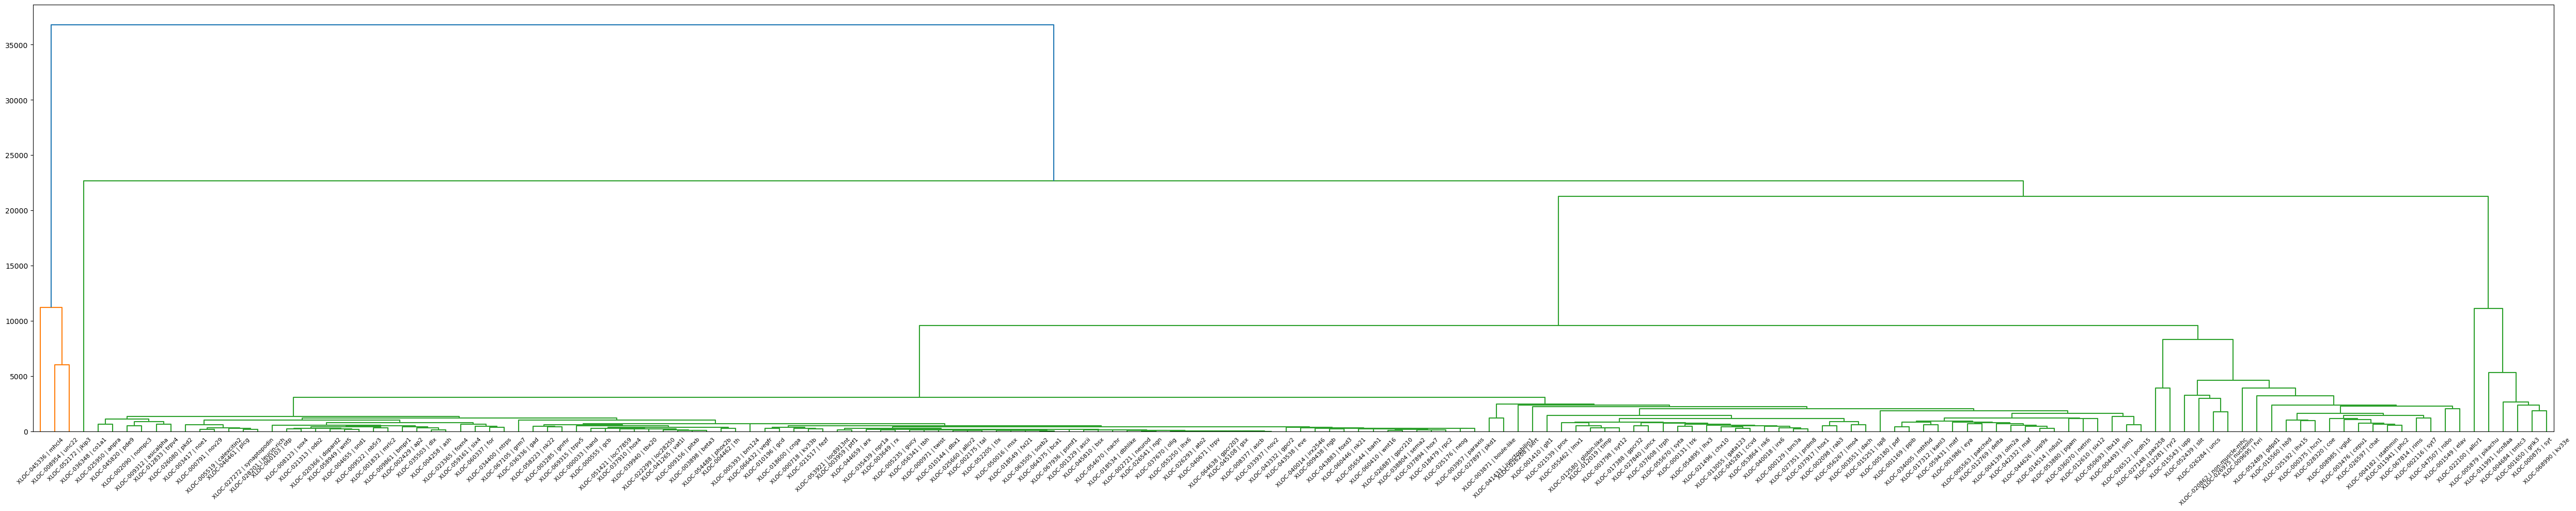

In [124]:
feature_linkage = linkage(platybrowser_aggregated.layers['sum'].T, method='ward', metric='euclidean')
fig, ax = plt.subplots(figsize=(50, 10))

# Plot the dendrogram with labels and rotation
feature_order = dendrogram(
    feature_linkage,
    ax=ax,
    labels=platybrowser_aggregated.var_names.to_list(), 
    leaf_rotation=45, 
    leaf_font_size=8
)['leaves']

ordered_feature_names = platybrowser_aggregated.var_names[feature_order].to_list()
print(f"Here is how the order starts: {ordered_feature_names[:10]}")
plt.tight_layout()
plt.show()

I will do a giant dotplot of what we have for Platybrowser. Let's define some arguments we want to play with from https://scanpy.readthedocs.io/en/stable/api/generated/classes/scanpy.pl.DotPlot.html
I will reuse them later.

In [125]:
extra_args = {
    "expression_cutoff": 0,
    "standard_scale": "group", # None #  "var"
    "mean_only_expressed": False
}

I will map tissue types to colors.

You get the big group names and the the clades. We could play with the order, but not for now. Some markers are super high everywhere, others like `unc-22` are good markers for a group like `Somatic musculature`. Some are super sparse.

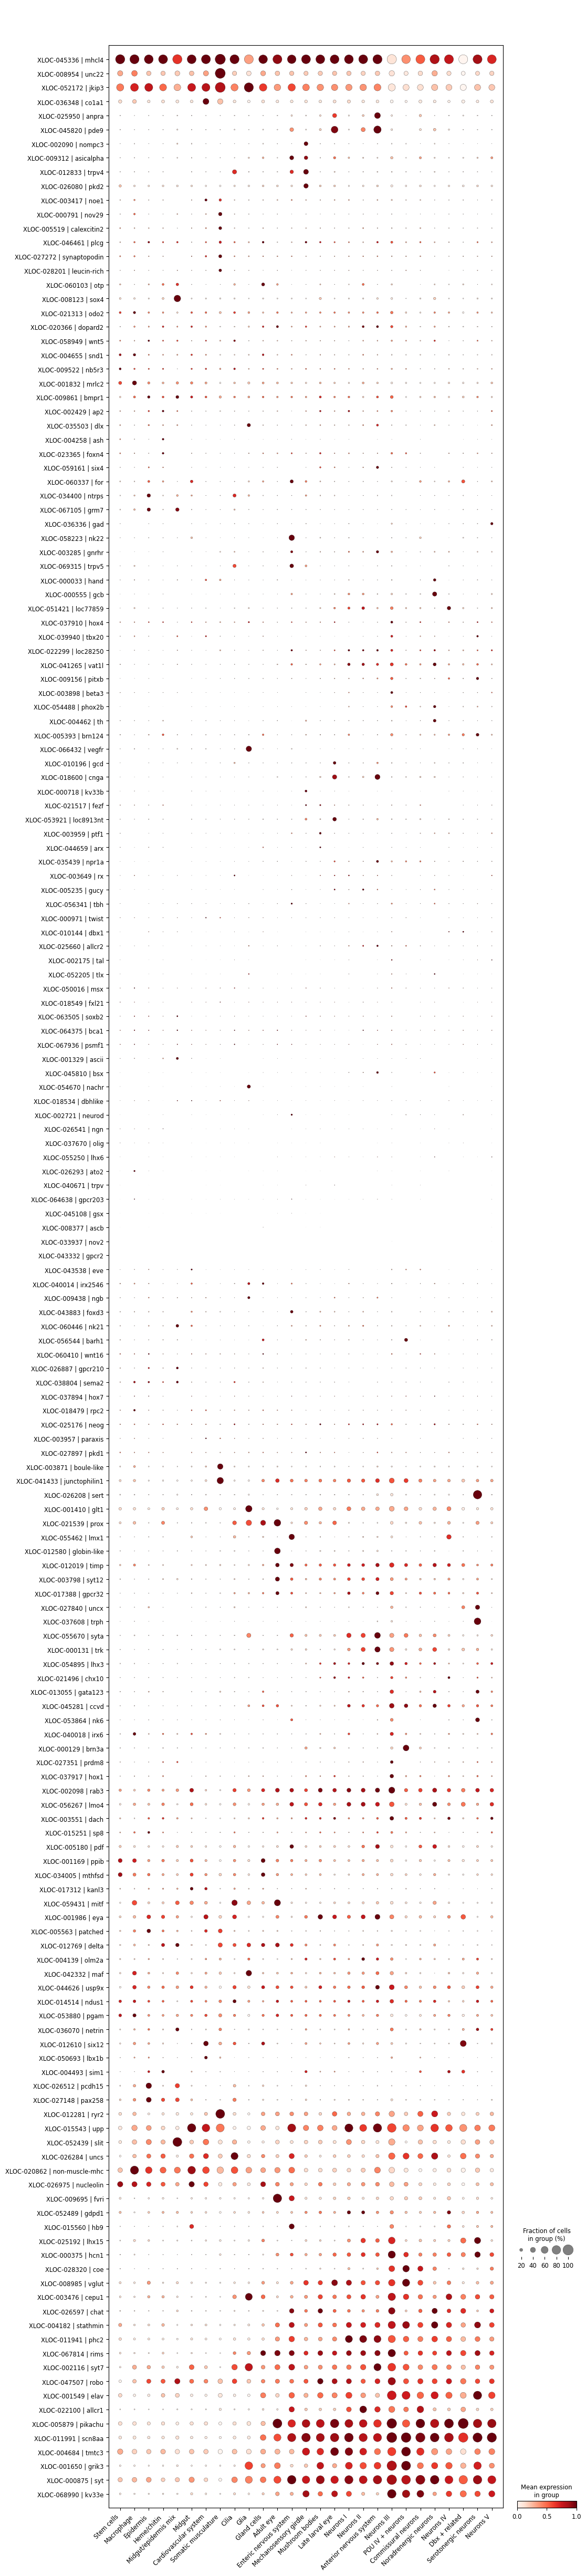

In [126]:
platybrowser_dotplot = sc.pl.dotplot(
    adata=subset_adata, 
    var_names=ordered_feature_names,
    groupby=["group_full"],
    return_fig=True,
    swap_axes=True,
    **extra_args
)

# Prettier plots
platybrowser_dotplot.make_figure()
ax = platybrowser_dotplot.get_axes()['mainplot_ax']
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

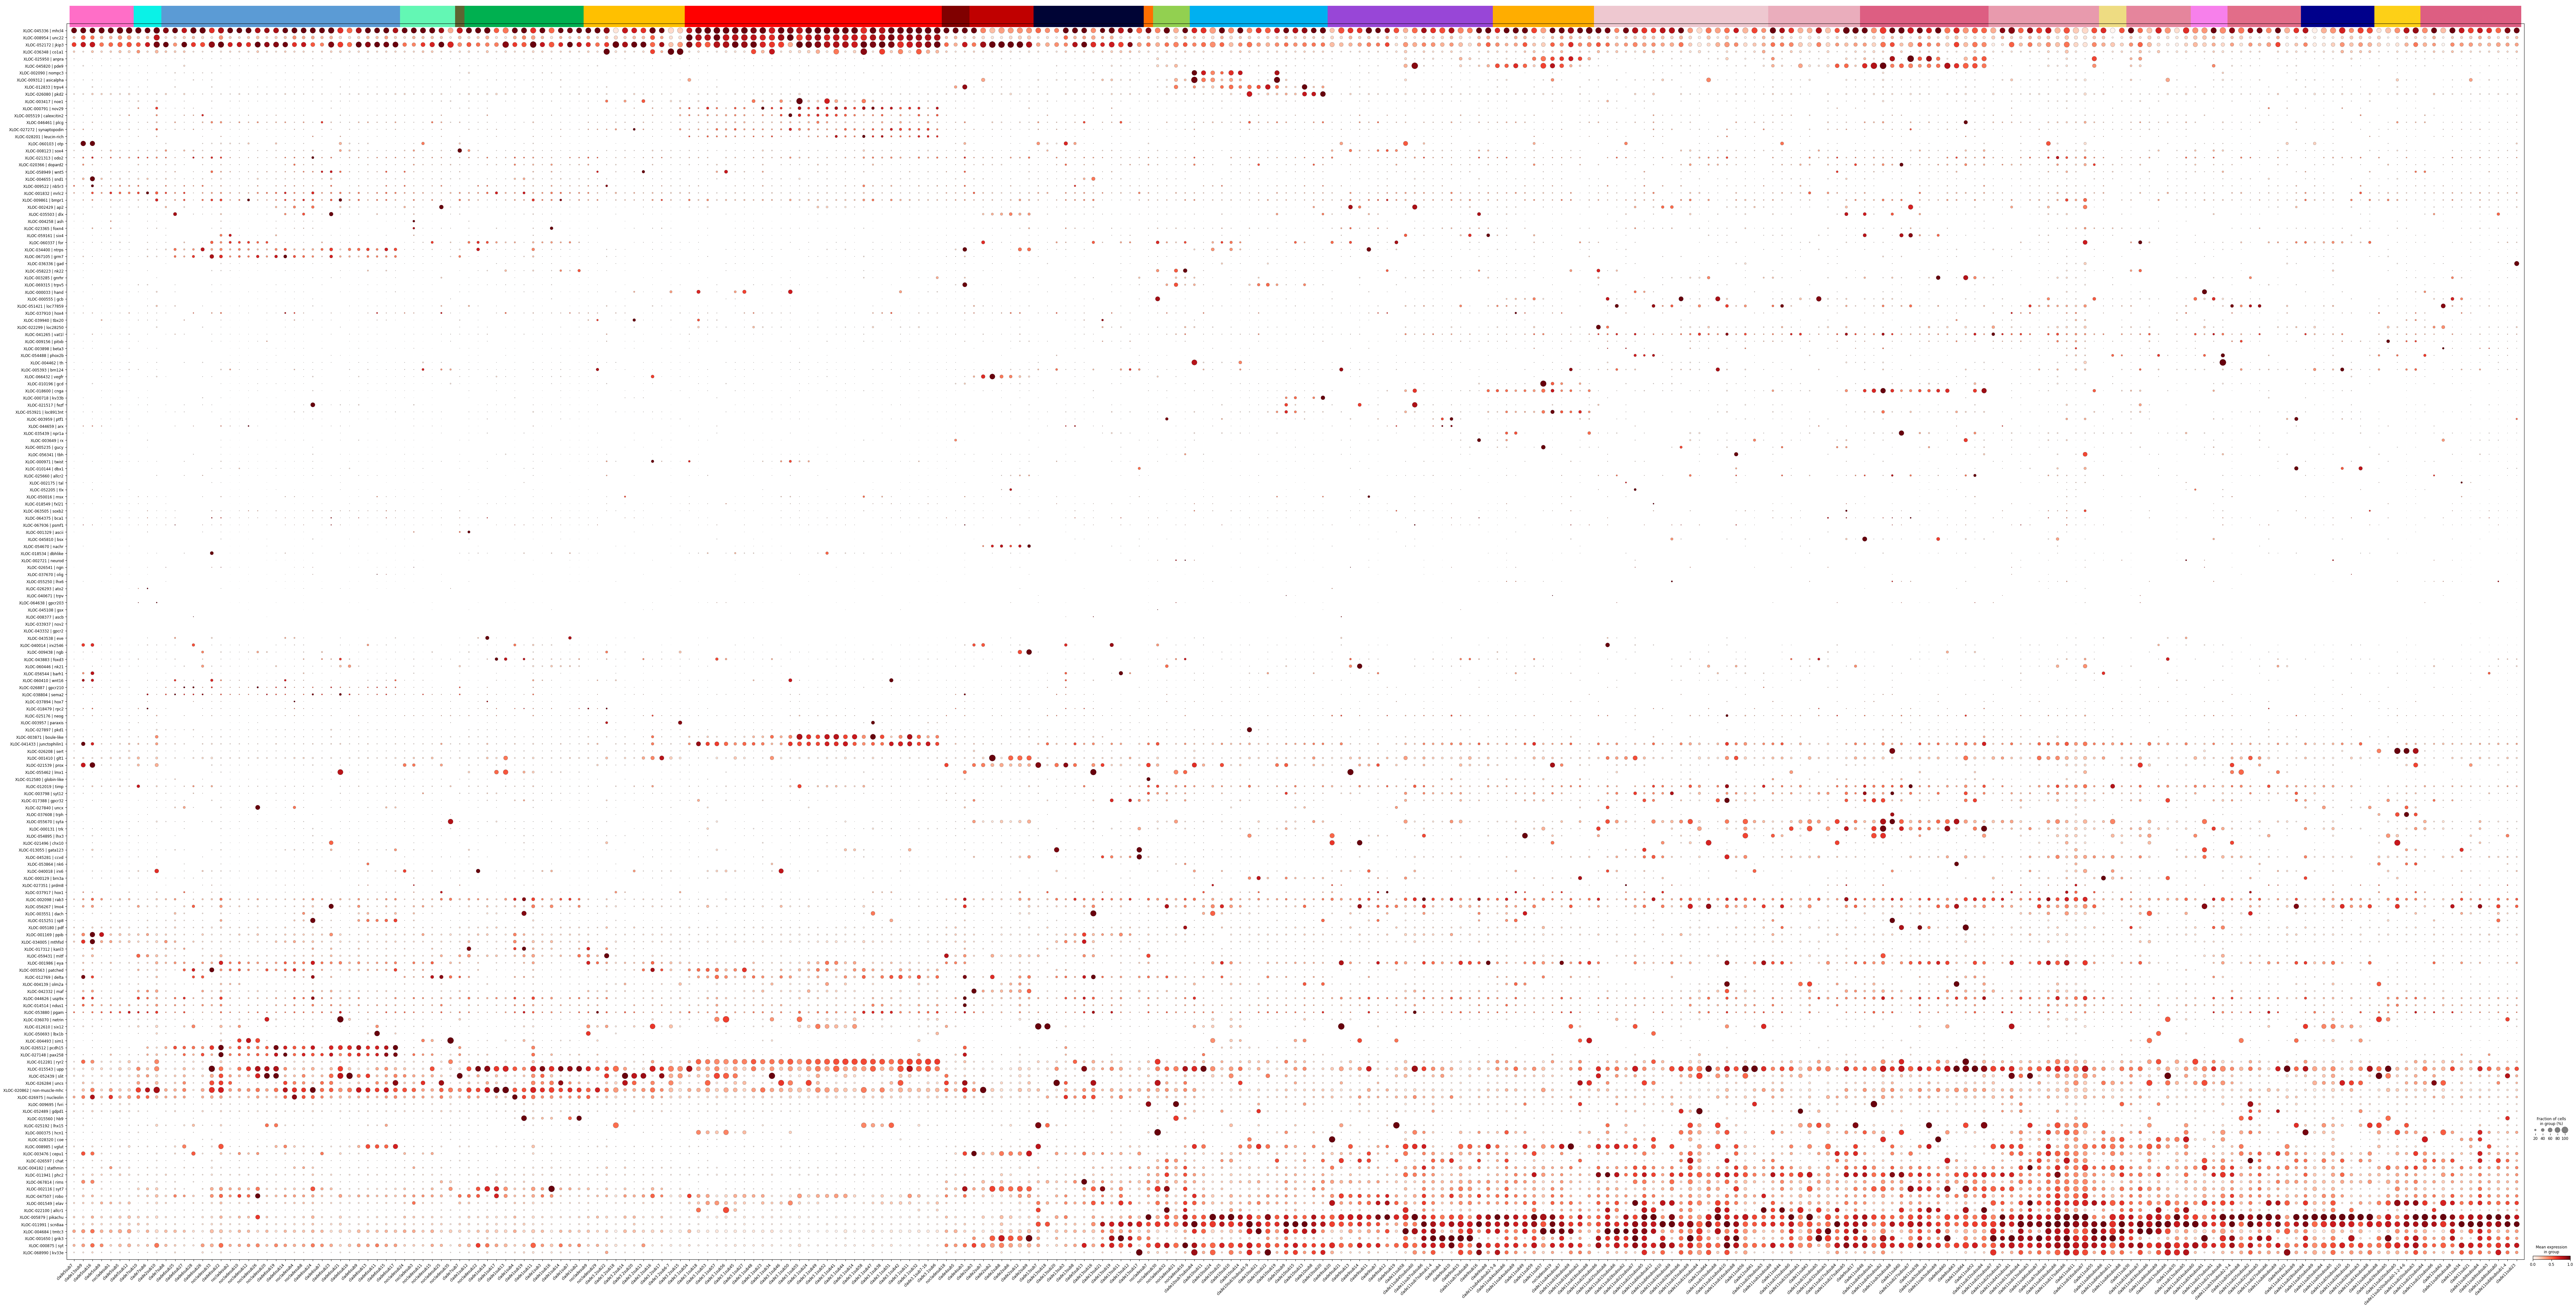

In [127]:
platybrowser_dotplot = sc.pl.dotplot(
    adata=subset_adata, 
    var_names=ordered_feature_names,
    groupby=["curated_high_res_annotations"],
    return_fig=True,
    swap_axes=True,
    **extra_args
)

# Prettier plots
platybrowser_dotplot.make_figure()
ax = platybrowser_dotplot.get_axes()['mainplot_ax']
fig = ax.get_figure()
# x-axis
xticks = ax.get_xticks()
xticklabels = [label.get_text() for label in ax.get_xticklabels()]
# color bars
bar_y_position = -3
bar_height = 3

for i, cell_type in enumerate(xticklabels):
    color = cell_types_metadata.loc[cell_type, 'group_color']
    rect = patches.Rectangle(
        xy=(xticks[i] - 0.5, bar_y_position),
        width=1,
        height=bar_height,
        facecolor=color,
        edgecolor='none',
        clip_on=False
    )
    ax.add_patch(rect)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
fig.subplots_adjust(bottom=0.25)
plt.show()

We can access info from the dotplot.

In [128]:
platybrowser_dotplot = sc.pl.dotplot(
    subset_adata, 
    subset_adata.var_names.to_list(),
    groupby=["group_full", "curated_high_res_annotations"], 
    return_fig=True,
    **extra_args
)

Following https://github.com/scverse/scanpy/blob/1.11.3/src/scanpy/plotting/_dotplot.py#L822-L1031 I can extract the dotplot information

In [129]:
obs_bool = platybrowser_dotplot.obs_tidy > extra_args["expression_cutoff"]

# dot_size -> fraction of cells, never changes
dot_size_df = (
    obs_bool.groupby(level=0, observed=True).sum()
        / obs_bool.groupby(level=0, observed=True).count()
)

# dot_color -> strength of expression but with scaled values, scaling can change!
if extra_args["mean_only_expressed"]:
    dot_color_df = (
        platybrowser_dotplot.obs_tidy.mask(~obs_bool)
            .groupby(level=0, observed=True)
            .mean()
            .fillna(0)
        )
else:
    dot_color_df = platybrowser_dotplot.obs_tidy.groupby(level=0, observed=True).mean()

# dot_color depends on the chosen scale
standard_scale = extra_args["standard_scale"]
if standard_scale == "group":
    dot_color_df = dot_color_df.sub(dot_color_df.min(1), axis=0)
    dot_color_df = dot_color_df.div(dot_color_df.max(1), axis=0).fillna(0)
elif standard_scale == "var":
    dot_color_df -= dot_color_df.min(0)
    dot_color_df = (dot_color_df / dot_color_df.max(0)).fillna(0)
elif standard_scale is None:
    pass
else:
    print("Unknown type for standard_scale, ignored")

Here is what you end up with:

In [130]:
dot_color_df.head()   # mean of SCALED expression value

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
group_full_curated_high_res_annotations,,,,,,,,,,,,,,,,,,,,,
Stem cells_clade5sub7,0.008575,0.023465,0.006809,0.029203,0.000000,0.000000,0.027298,0.295012,0.009783,0.135796,...,0.015235,0.0,0.007520,0.015784,0.040474,0.011261,0.096471,0.004923,0.000000,0.0
Stem cells_clade13sub9,0.011383,0.000000,0.048231,0.033948,0.000000,0.009854,0.000000,0.359410,0.000000,0.347147,...,0.013515,0.0,0.000000,0.072119,0.398993,0.046342,0.103999,0.000000,0.000000,0.0
Stem cells_clade5sub16,0.000000,0.024325,0.036512,0.042676,0.011482,0.000000,0.031302,0.497570,0.010434,0.851754,...,0.000000,0.0,0.000000,0.031613,0.417168,0.030213,0.156070,0.022083,0.000000,0.0
Stem cells_clade5sub9,0.007878,0.040882,0.012232,0.021952,0.000000,0.008095,0.023338,0.417698,0.003491,0.664948,...,0.012245,0.0,0.022251,0.004274,0.073129,0.002705,0.058184,0.008643,0.000000,0.0
Stem cells_nocladesub1,0.015570,0.030097,0.023688,0.019427,0.005033,0.003648,0.018589,0.212889,0.010367,0.189863,...,0.018812,0.0,0.010680,0.043584,0.064080,0.020586,0.066591,0.008782,0.001313,0.0


In [131]:
dot_size_df.head()  # Fraction of cells expressing

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5,XLOC-026293 | ato2,XLOC-043332 | gpcr2
group_full_curated_high_res_annotations,,,,,,,,,,,,,,,,,,,,,
Stem cells_clade5sub7,0.010676,0.021352,0.010676,0.032028,0.000000,0.000000,0.032028,0.295374,0.010676,0.156584,...,0.017794,0.0,0.007117,0.017794,0.049822,0.017794,0.099644,0.007117,0.000000,0.0
Stem cells_clade13sub9,0.016129,0.000000,0.048387,0.048387,0.000000,0.016129,0.000000,0.419355,0.000000,0.403226,...,0.016129,0.0,0.000000,0.096774,0.467742,0.048387,0.129032,0.000000,0.000000,0.0
Stem cells_clade5sub16,0.000000,0.043478,0.043478,0.065217,0.021739,0.000000,0.043478,0.543478,0.021739,0.739130,...,0.000000,0.0,0.000000,0.043478,0.478261,0.043478,0.173913,0.043478,0.000000,0.0
Stem cells_clade5sub9,0.011236,0.050562,0.022472,0.033708,0.000000,0.011236,0.028090,0.438202,0.005618,0.640449,...,0.016854,0.0,0.022472,0.011236,0.101124,0.005618,0.073034,0.011236,0.000000,0.0
Stem cells_nocladesub1,0.018945,0.035183,0.031123,0.023004,0.006766,0.004060,0.023004,0.246279,0.012179,0.225981,...,0.027064,0.0,0.013532,0.062246,0.078484,0.029770,0.082544,0.010825,0.001353,0.0


We load Platybrowser

In [132]:
em_unsorted_cols = pd.read_table("./prepped_data/platybrowser_counts.tsv", index_col="label_id")
# forgot to do this, I want alphabetical
em = em_unsorted_cols .sort_index(axis=1)
em.head()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-060446 | nk21,XLOC-063505 | soxb2,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5
label_id,,,,,,,,,,,,,,,,,,,,,
1.0,0.00146,0.001112,0.000066,0.002051,0.00648,0.001305,0.000604,0.037809,0.002245,0.0,...,0.009226,0.00068,0.000043,0.012019,0.01309,0.480433,0.009885,0.000325,0.003868,0.023110
2.0,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.00000,0.000000,0.000000,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000
3.0,0.00000,0.099017,0.000000,0.003640,0.00000,0.045504,0.000000,0.017474,0.000000,0.0,...,0.002184,0.00000,0.000000,0.000000,0.00000,0.949399,0.000000,0.046596,0.001092,0.002184
4.0,0.00000,0.011179,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.282520,0.00000,0.000000,0.000000,0.00000,0.994919,0.000000,0.000000,0.000000,0.000000
5.0,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.00000,0.000000,0.000000,0.00000,0.111111,0.000000,0.000000,0.000000,0.000000


In [133]:
em.describe()

,XLOC-000033 | hand,XLOC-000129 | brn3a,XLOC-000131 | trk,XLOC-000375 | hcn1,XLOC-000555 | gcb,XLOC-000718 | kv33b,XLOC-000791 | nov29,XLOC-000875 | syt,XLOC-000971 | twist,XLOC-001169 | ppib,...,XLOC-060446 | nk21,XLOC-063505 | soxb2,XLOC-064375 | bca1,XLOC-064638 | gpcr203,XLOC-066432 | vegfr,XLOC-067105 | grm7,XLOC-067814 | rims,XLOC-067936 | psmf1,XLOC-068990 | kv33e,XLOC-069315 | trpv5
count,32699.000000,32699.00000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,...,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000,32699.000000
mean,0.033868,0.03728,0.016099,0.111146,0.022723,0.105217,0.014800,0.185862,0.043425,0.013717,...,0.015432,0.012909,0.012441,0.003623,0.011237,0.141337,0.005611,0.030821,0.142991,0.022701
std,0.158917,0.15533,0.103675,0.260767,0.119528,0.261934,0.095981,0.349794,0.169259,0.102245,...,0.104937,0.089945,0.094138,0.048913,0.077986,0.306049,0.060780,0.135418,0.306331,0.118421
min,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.00000,0.000000,0.008433,0.000000,0.000000,0.000000,0.122218,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.029478,0.000000,0.000000,0.014748,0.000000
max,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Clustering first

In [134]:
em_transposed = em.T
# Cluster
row_linkage = linkage(em_transposed, method='ward', metric='euclidean')
col_linkage = linkage(em_transposed.T, method='ward', metric='euclidean')
# Extract the final order
row_order = dendrogram(row_linkage, no_plot=True)['leaves']
col_order = dendrogram(col_linkage, no_plot=True)['leaves']
# Reorder the rows and columns
ordered_indices = em_transposed.index[row_order]
ordered_columns = em_transposed.columns[col_order]
em_reordered = em_transposed.reindex(index=ordered_indices, columns=ordered_columns)

We take a look at our heatmap.

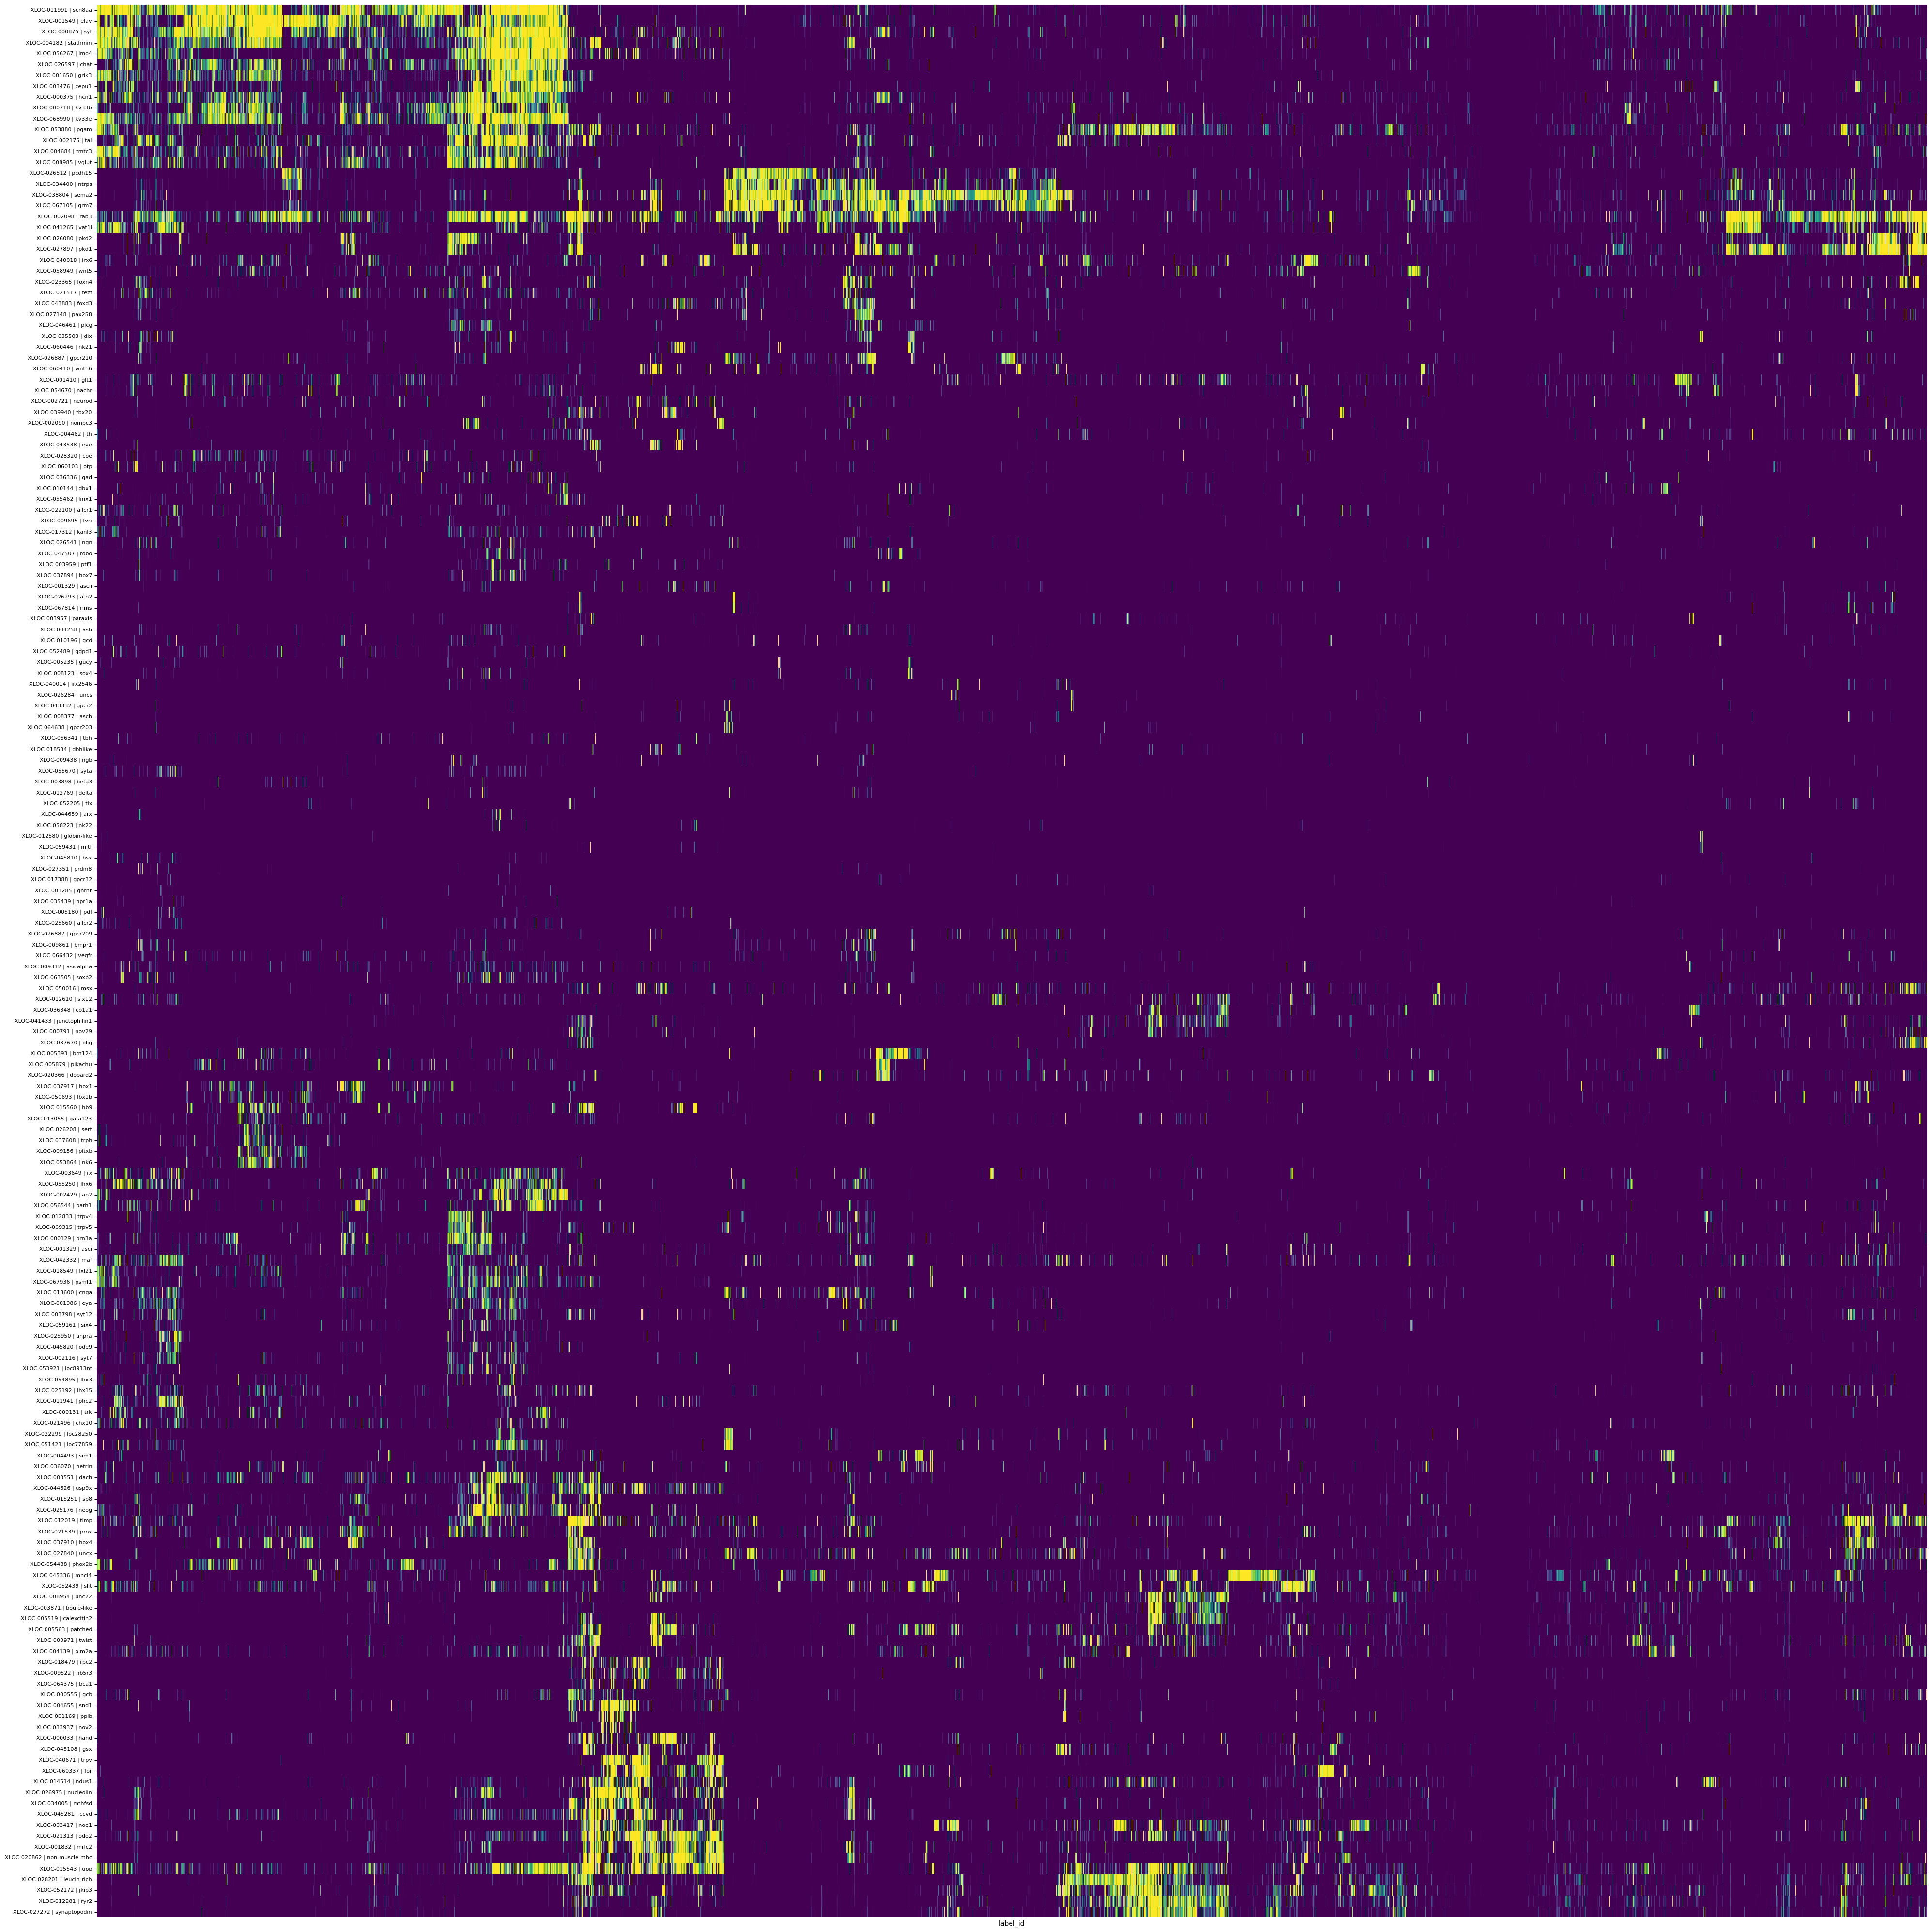

In [135]:

# Formatting
fig, ax = plt.subplots(figsize=(40, 40))

sns.heatmap(
    em_reordered,
    ax=ax,
    cmap='viridis',
    xticklabels=False, 
    cbar=False
)
ax.tick_params(axis='y', labelsize=8) # Adjust y-axis font size if needed
ax.tick_params(axis='x', rotation=90, labelsize=8) # Rotate x-axis labels
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()